In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import numpy as np


In [6]:
df=pd.read_csv(r"C:\Users\User\Desktop\me journey\aml_lab_preparation\data\Salary_Data.csv")
df.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


In [7]:
x=df.iloc[:,[0]].values
y=df.iloc[:,-1].values

In [8]:
x_train,x_test,y_train,y_test=train_test_split(
    x,y,test_size=0.25,random_state=0
)

In [9]:
model=LinearRegression()
model.fit(x_train,y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [10]:
y_pred=model.predict(x_test)

In [11]:
print(model.intercept_)
print(model.coef_[0])

26986.691316737248
9379.710491946016


In [12]:
print("y =", model.intercept_, "+", model.coef_[0], "* x")

y = 26986.691316737248 + 9379.710491946016 * x


In [13]:
mae=mean_absolute_error(y_test,y_pred)
print(mae)

3508.5455930660555


In [15]:
mse=mean_squared_error(y_test,y_pred)
print(mse)

22407940.143340684


In [19]:
rmse=np.sqrt(mse)
print(rmse)
r_square=r2_score(y_test,y_pred)
print(r_square)

4733.70258289858
0.9779208335417602


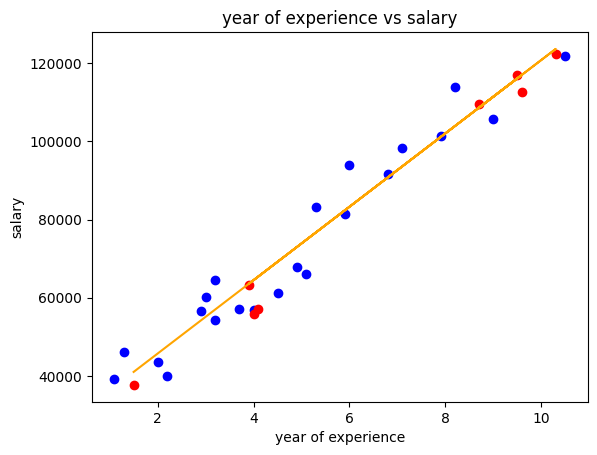

In [27]:
import matplotlib.pyplot as plt

plt.scatter(x_train, y_train, color="blue")
plt.scatter(x_test, y_test, color="red")

plt.plot(x_test, y_pred, color="orange")

plt.xlabel("year of experience")
plt.ylabel("salary")
plt.title("year of experience vs salary")
plt.show()

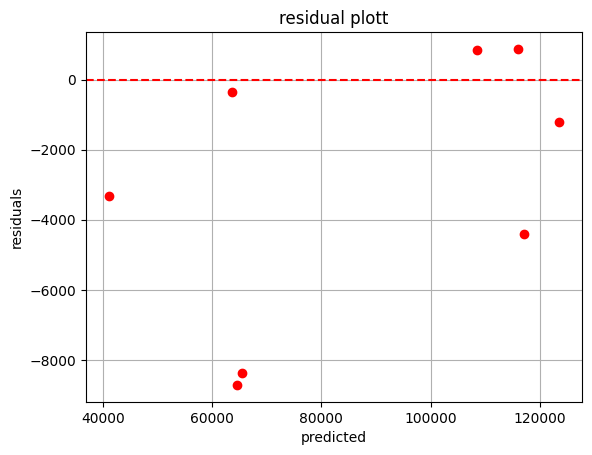

In [30]:
residuals = y_test - y_pred

plt.scatter(y_pred, residuals, color="red")
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("predicted")
plt.ylabel("residuals")
plt.title("residual plott")
plt.grid(True)
plt.show()